# KELOMPOK 4 DATA WRANGLING (PRE-PROCESSING & ANALISIS MULTIVARIAT)

1. Ivanagita Mayang Palupi (**230**31554**009**)
2. Anugerah Sigit Hadinata (**250**31554**032**)
3. Athallah Putra Ramadhani Singgih (**250**31554**067**)
4. Achmad Wahab Abdullah (**250**31554**222**)
5. Muhammad Syihabudin (**250**31554**188**)

#0. Inisiasi Data Awal

DataSet yang digunakan adalah data **global_freelancers_raw.csv** yang diambil dari Kagggle *(https://www.kaggle.com/datasets/urvishahir/global-freelancers-raw-dataset)*

In [96]:
import pandas as pd

# 1. Membaca data mentah dari file CSV
df = pd.read_csv("global_freelancers_raw.csv")

print("Sample Data Raw")
display(df.head())

Sample Data Raw


,freelancer_ID,name,gender,age,country,language,primary_skill,years_of_experience,hourly_rate (USD),rating,is_active,client_satisfaction
0,FL250001,Ms. Nicole Kidd,f,52.0,Italy,Italian,Blockchain Development,11.0,100,NaN,0,NaN
1,FL250002,Vanessa Garcia,FEMALE,52.0,Australia,English,Mobile Apps,34.0,USD 100,3.3,1,84%
2,FL250003,Juan Nelson,male,53.0,Germany,German,Graphic Design,31.0,50,0.0,N,71%
3,FL250004,Amanda Spencer,F,38.0,Australia,English,Web Development,4.0,$40,1.5,N,90%
4,FL250005,Lynn Curtis DDS,female,53.0,Germany,German,Web Development,27.0,30,4.8,0,83%


In [97]:
print("\nInformasi Struktur Data")
df.info()


Informasi Struktur Data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   freelancer_ID        1000 non-null   object 
 1   name                 1000 non-null   object 
 2   gender               1000 non-null   object 
 3   age                  970 non-null    float64
 4   country              1000 non-null   object 
 5   language             1000 non-null   object 
 6   primary_skill        1000 non-null   object 
 7   years_of_experience  949 non-null    float64
 8   hourly_rate (USD)    906 non-null    object 
 9   rating               899 non-null    float64
 10  is_active            911 non-null    object 
 11  client_satisfaction  824 non-null    object 
dtypes: float64(3), object(9)
memory usage: 93.9+ KB


# 1. Preprocessing

In [98]:
import numpy as np
import pandas as pd

# 1. Membaca data mentah
df = pd.read_csv("global_freelancers_raw.csv")

# 2. Standarisasi nama kolom
df.columns = [
    col.strip().lower().replace(" ", "_").replace("(", "").replace(")", "")
    for col in df.columns
]

# 3. Membersihkan hourly_rate_usd menjadi float
df["hourly_rate_usd"] = pd.to_numeric(
    df["hourly_rate_usd"]
    .astype(str)
    .str.replace("USD", "", regex=False)
    .str.replace("$", "", regex=False)
    .str.strip(),
    errors="coerce",
)

# 4. Membersihkan client_satisfaction menjadi float
df["client_satisfaction"] = pd.to_numeric(
    df["client_satisfaction"]
    .astype(str)
    .str.replace("%", "", regex=False)
    .str.strip(),
    errors="coerce",
)

# 5. Penyeragaman kategori gender
gender_map = {"f": "Female", "female": "Female", "m": "Male", "male": "Male"}
df["gender"] = df["gender"].astype(str).str.strip().str.lower().map(gender_map)

# 6. Penyeragaman is_active menjadi biner 1 dan 0
def parse_active(val):
    if pd.isna(val):
        return np.nan
    v = str(val).strip().lower()
    if v in ["1", "true", "yes", "y"]:
        return 1
    if v in ["0", "false", "no", "n"]:
        return 0
    return np.nan

df["is_active"] = df["is_active"].apply(parse_active)

# 7. Penanganan missing value
# is_active adalah label, sehingga baris yang kosong dibuang (tidak diisi tebakan).
n_awal = len(df)
df = df.dropna(subset=["is_active"]).copy()
df["is_active"] = df["is_active"].astype(int)
print(f"Baris dibuang karena is_active kosong : {n_awal - len(df)}")

# Fitur numerik diisi median agar tidak terpengaruh pencilan
numeric_cols = ["age", "years_of_experience", "hourly_rate_usd", "rating", "client_satisfaction"]
print("\nMissing value per kolom numerik (sebelum imputasi):")
print(df[numeric_cols].isna().sum().to_string())
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# 8. Pemeriksaan nilai 0 yang mencurigakan (hanya dicatat, belum diubah)
print(f"\nBaris dengan rating == 0            : {(df['rating'] == 0).sum()}")
print(f"Baris dengan years_of_experience == 0: {(df['years_of_experience'] == 0).sum()}")
print("Rating 0 bisa berarti 'belum ada ulasan', bukan nilai sebenarnya. Perlu dicek di data sumber.")

# 9. Validasi akhir
assert df[numeric_cols + ["is_active"]].notna().all().all(), "Masih ada missing value"

# 10. Menyimpan data bersih
df.to_csv("global_freelancers_preprocessing.csv", index=False)
print("\nDimensi data setelah preprocessing:", df.shape)

Baris dibuang karena is_active kosong : 89

Missing value per kolom numerik (sebelum imputasi):
age                     28
years_of_experience     47
hourly_rate_usd         89
rating                  94
client_satisfaction    159

Baris dengan rating == 0            : 135
Baris dengan years_of_experience == 0: 65
Rating 0 bisa berarti 'belum ada ulasan', bukan nilai sebenarnya. Perlu dicek di data sumber.

Dimensi data setelah preprocessing: (911, 12)


# 2. Normalisasi

In [99]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from IPython.display import display

# Ambil data hasil preprocessing dari memori, atau dari file jika sesi baru
try:
    df_pre = df.copy()
except NameError:
    df_pre = pd.read_csv("global_freelancers_preprocessing.csv")

cols_to_normalize = ["age", "years_of_experience", "hourly_rate_usd", "rating", "client_satisfaction"]

# Validasi awal
missing_cols = [c for c in cols_to_normalize if c not in df_pre.columns]
assert not missing_cols, f"Kolom tidak ditemukan: {missing_cols}"
assert df_pre[cols_to_normalize].notna().all().all(), "Masih ada missing value, jalankan preprocessing dulu"
assert all(pd.api.types.is_numeric_dtype(df_pre[c]) for c in cols_to_normalize), "Ada kolom non-numerik"

print("Dimensi data :", df_pre.shape)
print("\n=== STATISTIK SEBELUM NORMALISASI ===")
display(df_pre[cols_to_normalize].describe().round(3))

# Min-Max Scaling ke rentang 0-1
scaler = MinMaxScaler(feature_range=(0, 1))
df_normalized = df_pre.copy()
df_normalized[cols_to_normalize] = scaler.fit_transform(df_pre[cols_to_normalize])

scaler_params = pd.DataFrame({
    "data_min": scaler.data_min_,
    "data_max": scaler.data_max_,
    "data_range": scaler.data_range_,
}, index=cols_to_normalize)

print("=== PARAMETER MIN-MAX SCALER ===")
display(scaler_params)

print("\n=== 5 DATA PERTAMA SETELAH NORMALISASI ===")
display(df_normalized.head())
df_normalized.to_csv("global_freelancers_normalisasi.csv", index=False)

Dimensi data : (911, 12)

=== STATISTIK SEBELUM NORMALISASI ===


,age,years_of_experience,hourly_rate_usd,rating,client_satisfaction
count,911.000,911.000,911.000,911.000,911.000
mean,40.328,11.141,51.625,2.493,79.155
std,11.805,9.401,26.337,1.473,10.385
min,20.000,0.000,20.000,0.000,60.000
25%,31.000,3.000,30.000,1.500,71.000
50%,41.000,9.000,40.000,2.500,79.000
75%,51.000,17.000,75.000,3.600,87.000
max,60.000,41.000,100.000,5.000,100.000


=== PARAMETER MIN-MAX SCALER ===


,data_min,data_max,data_range
age,20.0,60.0,40.0
years_of_experience,0.0,41.0,41.0
hourly_rate_usd,20.0,100.0,80.0
rating,0.0,5.0,5.0
client_satisfaction,60.0,100.0,40.0



=== 5 DATA PERTAMA SETELAH NORMALISASI ===


,freelancer_id,name,gender,age,country,language,primary_skill,years_of_experience,hourly_rate_usd,rating,is_active,client_satisfaction
0,FL250001,Ms. Nicole Kidd,Female,0.800,Italy,Italian,Blockchain Development,0.268293,1.000,0.50,0,0.475
1,FL250002,Vanessa Garcia,Female,0.800,Australia,English,Mobile Apps,0.829268,1.000,0.66,1,0.600
2,FL250003,Juan Nelson,Male,0.825,Germany,German,Graphic Design,0.756098,0.375,0.00,0,0.275
3,FL250004,Amanda Spencer,Female,0.450,Australia,English,Web Development,0.097561,0.250,0.30,0,0.750
4,FL250005,Lynn Curtis DDS,Female,0.825,Germany,German,Web Development,0.658537,0.125,0.96,0,0.575


# 3. Silhouette Score Sebelum Cleaning

Silhouette score mengukur seberapa rapat dan terpisah klaster hasil K-Means, dengan rentang -1 sampai 1. Nilai di atas 0,5 umumnya menunjukkan struktur klaster yang kuat, sedangkan nilai di bawah 0,25 menunjukkan struktur yang lemah. Perbandingan sebelum dan sesudah cleaning dilakukan di bagian 5.3, karena cleaning baru dilakukan pada bagian 5.2.

In [100]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from IPython.display import display

X = df_normalized[cols_to_normalize]

# Memilih jumlah klaster: silhouette untuk beberapa nilai k
sil_by_k = {}
for k in range(2, 9):
    labels_k = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)
    sil_by_k[k] = silhouette_score(X, labels_k)
print("=== SILHOUETTE SEBELUM CLEANING UNTUK BEBERAPA NILAI k ===")
display(pd.Series(sil_by_k, name="silhouette").round(4).to_frame())

# Nilai k = 3 yang digunakan pada laporan
kmeans_awal = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_awal = kmeans_awal.fit_predict(X)
sil_score_awal = silhouette_score(X, labels_awal)
print(f"\nDimensi data sebelum cleaning : {X.shape}")
print(f"Silhouette Score (k = 3)      : {sil_score_awal:.4f}")

=== SILHOUETTE SEBELUM CLEANING UNTUK BEBERAPA NILAI k ===


,silhouette
2,0.2479
3,0.2193
4,0.2008
5,0.2080
6,0.1997
7,0.1945
8,0.2009



Dimensi data sebelum cleaning : (911, 5)
Silhouette Score (k = 3)      : 0.2193


# 4. Analisis Univariat

In [101]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

try:
    df_uni = df_pre.copy()
except NameError:
    df_uni = pd.read_csv("global_freelancers_preprocessing.csv")

# Label untuk analisis kategorikal. Kolom is_active asli tetap dipakai di analisis multivariat.
df_uni["status_aktif"] = df_uni["is_active"].map({1: "Aktif", 0: "Tidak aktif"})

# Variabel numerik kontinu. is_active tidak dimasukkan karena biner.
num_cols_uni = ["age", "years_of_experience", "hourly_rate_usd", "rating", "client_satisfaction"]
# freelancer_id dan name adalah identifier, bukan variabel analisis.
cat_cols_uni = ["gender", "country", "language", "primary_skill", "status_aktif"]

print("Dimensi data:", df_uni.shape)
print("Variabel numerik    :", num_cols_uni)
print("Variabel kategorikal:", cat_cols_uni)

Dimensi data: (911, 13)
Variabel numerik    : ['age', 'years_of_experience', 'hourly_rate_usd', 'rating', 'client_satisfaction']
Variabel kategorikal: ['gender', 'country', 'language', 'primary_skill', 'status_aktif']


### 4.1 Statistik Deskriptif Variabel Numerik

Statistik deskriptif merangkum jumlah data, rata-rata, simpangan baku, nilai minimum, kuartil, median, dan maksimum. Statistik ini menunjukkan pusat data, variasi, dan rentang nilai tiap variabel.

In [102]:
display(df_uni[num_cols_uni].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
age,911.0,40.328,11.805,20.0,31.0,41.0,51.0,60.0
years_of_experience,911.0,11.141,9.401,0.0,3.0,9.0,17.0,41.0
hourly_rate_usd,911.0,51.625,26.337,20.0,30.0,40.0,75.0,100.0
rating,911.0,2.493,1.473,0.0,1.5,2.5,3.6,5.0
client_satisfaction,911.0,79.155,10.385,60.0,71.0,79.0,87.0,100.0


### 4.2 Distribusi Frekuensi Variabel Kategorikal

Tabel frekuensi menampilkan jumlah dan persentase tiap kategori.

In [103]:
for col in cat_cols_uni:
    print(f"=== Distribusi {col} ===")
    freq = df_uni[col].value_counts(dropna=False).rename("frekuensi").to_frame()
    freq["persentase (%)"] = (freq["frekuensi"] / len(df_uni) * 100).round(2)
    display(freq)

=== Distribusi gender ===


,frekuensi,persentase (%)
gender,,
Male,472,51.81
Female,439,48.19


=== Distribusi country ===


,frekuensi,persentase (%)
country,,
South Korea,61,6.70
Canada,61,6.70
Germany,49,5.38
United Kingdom,48,5.27
Netherlands,46,5.05
Mexico,45,4.94
China,45,4.94
United States,44,4.83
Australia,43,4.72


=== Distribusi language ===


,frekuensi,persentase (%)
language,,
English,196,21.51
Spanish,129,14.16
Korean,61,6.70
German,49,5.38
Dutch,46,5.05
Mandarin,45,4.94
Indonesian,43,4.72
Turkish,42,4.61
Hindi,41,4.50


=== Distribusi primary_skill ===


,frekuensi,persentase (%)
primary_skill,,
UI/UX Design,103,11.31
DevOps,102,11.20
Blockchain Development,96,10.54
Mobile Apps,93,10.21
Web Development,92,10.10
Data Analysis,89,9.77
AI,88,9.66
Graphic Design,85,9.33
Cybersecurity,84,9.22


=== Distribusi status_aktif ===


,frekuensi,persentase (%)
status_aktif,,
Tidak aktif,465,51.04
Aktif,446,48.96


### 4.3 Pemeriksaan Redundansi `language` dan `country`

Jika setiap negara hanya memiliki satu bahasa, maka `language` tidak memberi informasi tambahan terhadap `country`. Dalam kasus itu, kedua variabel tidak boleh dimasukkan bersamaan ke model karena menimbulkan multikolinearitas.

In [104]:
jumlah_bahasa_per_negara = df_uni.groupby("country")["language"].nunique()
print("Jumlah bahasa berbeda per negara (maks):", jumlah_bahasa_per_negara.max())
display(jumlah_bahasa_per_negara.to_frame("jumlah_bahasa"))

Jumlah bahasa berbeda per negara (maks): 1


,jumlah_bahasa
country,
Argentina,1
Australia,1
Brazil,1
Canada,1
China,1
Egypt,1
France,1
Germany,1
India,1


### 4.4 Visualisasi Variabel Numerik

Histogram menunjukkan bentuk distribusi, sedangkan boxplot menunjukkan median, rentang antarkuartil, dan kemungkinan pencilan. Pencilan pada tahap ini hanya dicatat dan belum otomatis dihapus.

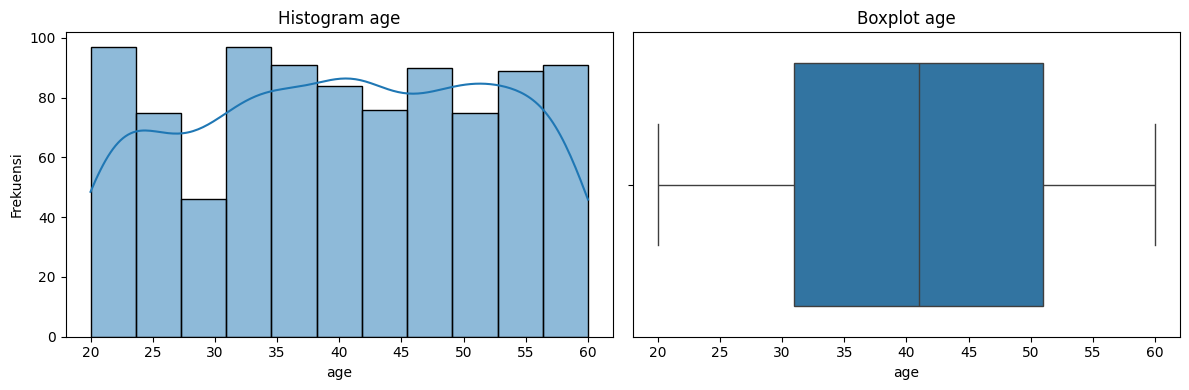

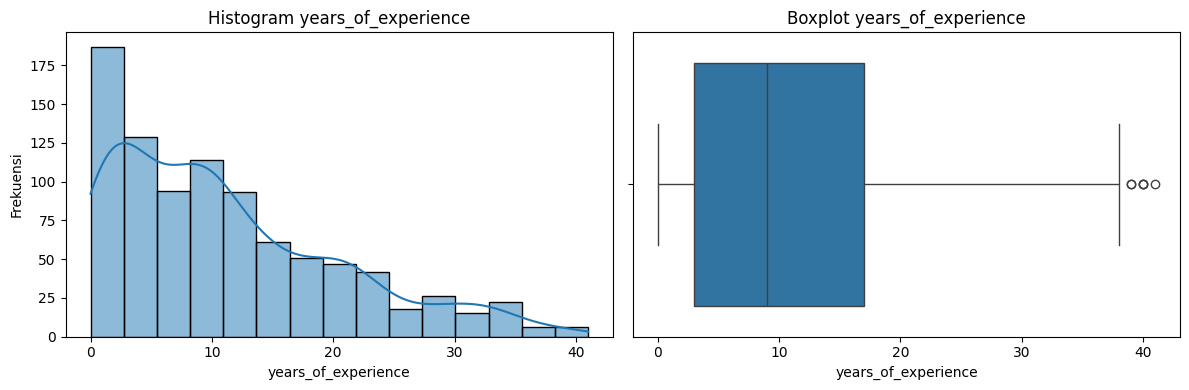

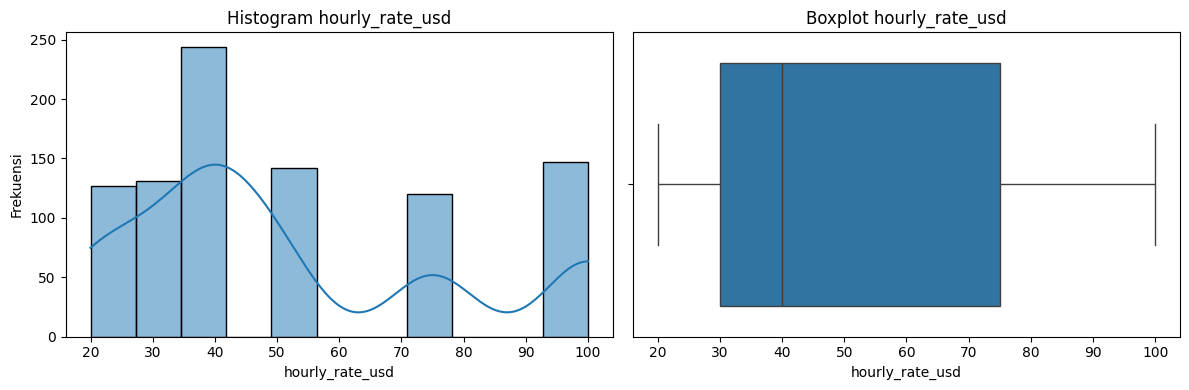

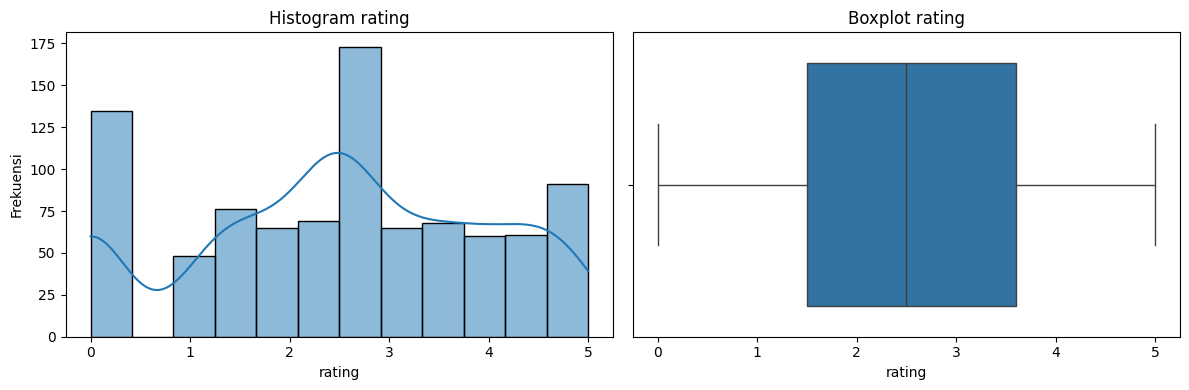

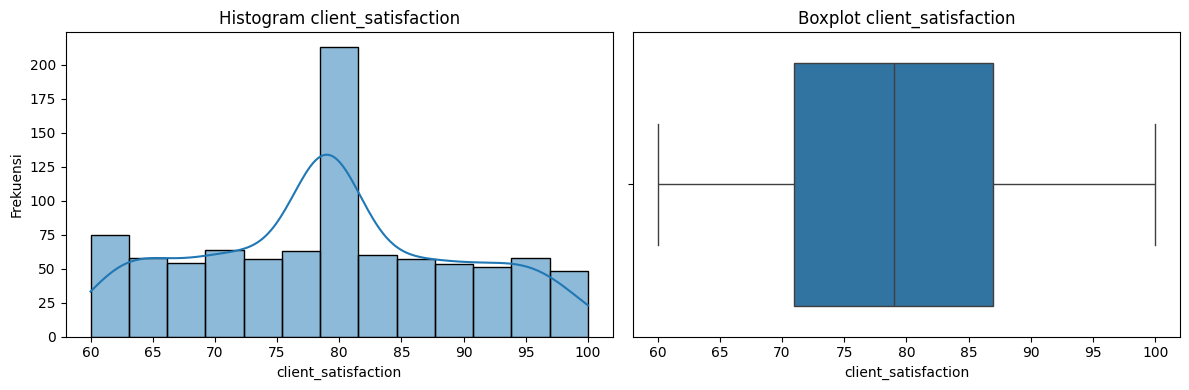

In [105]:
for col in num_cols_uni:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(data=df_uni, x=col, kde=True, ax=axes[0])
    axes[0].set_title(f"Histogram {col}")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Frekuensi")

    sns.boxplot(data=df_uni, x=col, ax=axes[1])
    axes[1].set_title(f"Boxplot {col}")
    axes[1].set_xlabel(col)

    plt.tight_layout()
    plt.show()

### 4.5 Visualisasi Variabel Kategorikal

Diagram batang membandingkan jumlah data tiap kategori. Semua variabel kategorikal yang dipilih memiliki jumlah kategori kecil, sehingga semuanya dapat ditampilkan.

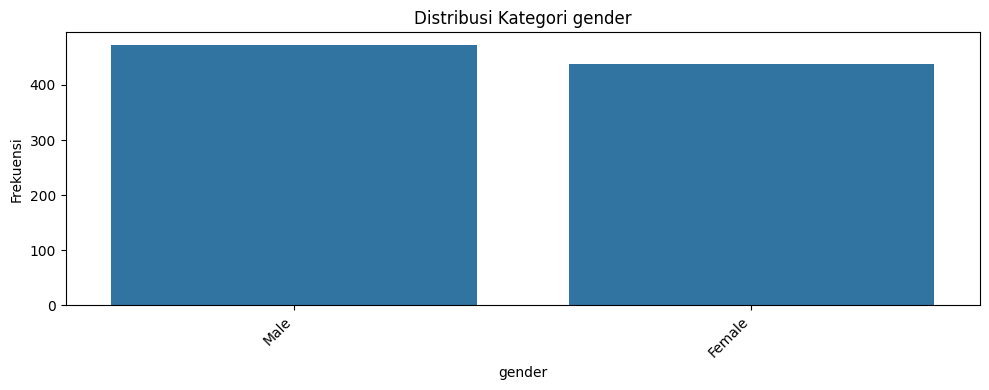

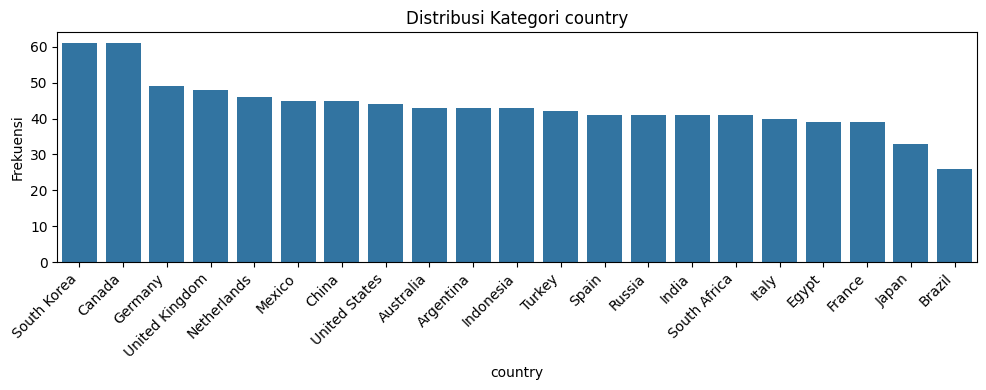

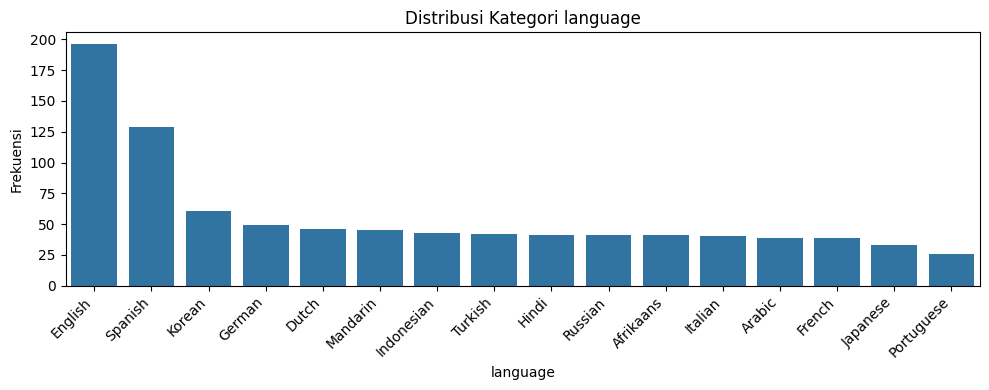

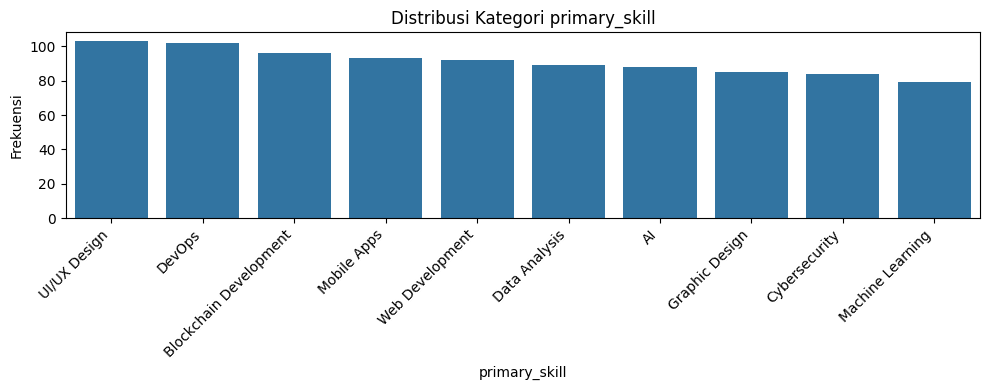

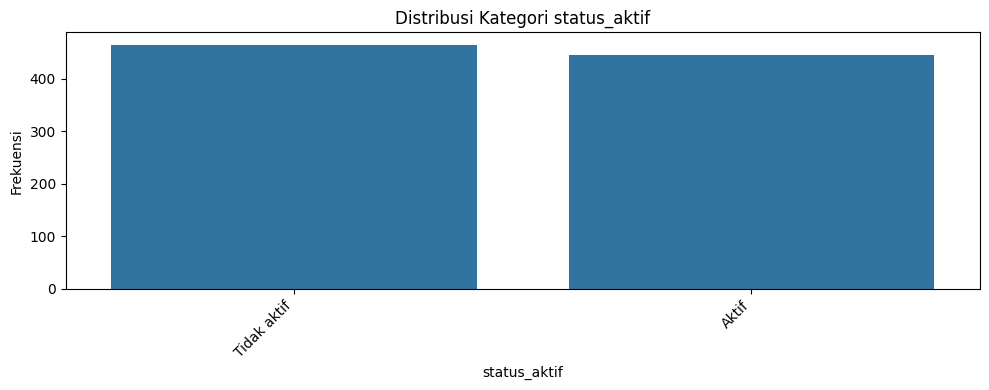

In [106]:
for col in cat_cols_uni:
    urutan = df_uni[col].value_counts(dropna=False).index
    plt.figure(figsize=(10, 4))
    sns.countplot(data=df_uni, x=col, order=urutan)
    plt.title(f"Distribusi Kategori {col}")
    plt.xlabel(col)
    plt.ylabel("Frekuensi")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### 4.6 Deteksi Outlier Univariat dengan IQR (hanya informasi)

Metode IQR menandai nilai di luar batas `Q1 - 1,5·IQR` dan `Q3 + 1,5·IQR`. Metode ini hanya melihat satu variabel dalam satu waktu, sehingga kombinasi nilai yang janggal tidak akan terdeteksi di sini.

In [107]:
Q1 = df_uni[num_cols_uni].quantile(0.25)
Q3 = df_uni[num_cols_uni].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_iqr = pd.DataFrame({
    "lower_bound": lower,
    "upper_bound": upper,
    "jumlah_outlier": ((df_uni[num_cols_uni] < lower) | (df_uni[num_cols_uni] > upper)).sum(),
})
outlier_iqr["persen_outlier"] = (outlier_iqr["jumlah_outlier"] / len(df_uni) * 100).round(2)

print("RINGKASAN OUTLIER (IQR)")
display(outlier_iqr)

RINGKASAN OUTLIER (IQR)


,lower_bound,upper_bound,jumlah_outlier,persen_outlier
age,1.00,81.00,0,0.00
years_of_experience,-18.00,38.00,6,0.66
hourly_rate_usd,-37.50,142.50,0,0.00
rating,-1.65,6.75,0,0.00
client_satisfaction,47.00,111.00,0,0.00


# 5. Analisis Multivariat

### 5.1 Korelasi dan Pola Tarif

Bagian ini memeriksa apakah pengalaman atau usia memengaruhi tarif, baik secara keseluruhan maupun per skill. Koefisien korelasi per skill dilaporkan dengan jumlah sampel (`n`), karena korelasi pada kelompok kecil tidak stabil.

,age,years_of_experience,hourly_rate_usd,rating,client_satisfaction
age,1.00,0.60,0.06,-0.01,-0.03
years_of_experience,0.60,1.00,0.05,0.03,-0.05
hourly_rate_usd,0.06,0.05,1.00,0.06,-0.03
rating,-0.01,0.03,0.06,1.00,-0.01
client_satisfaction,-0.03,-0.05,-0.03,-0.01,1.00


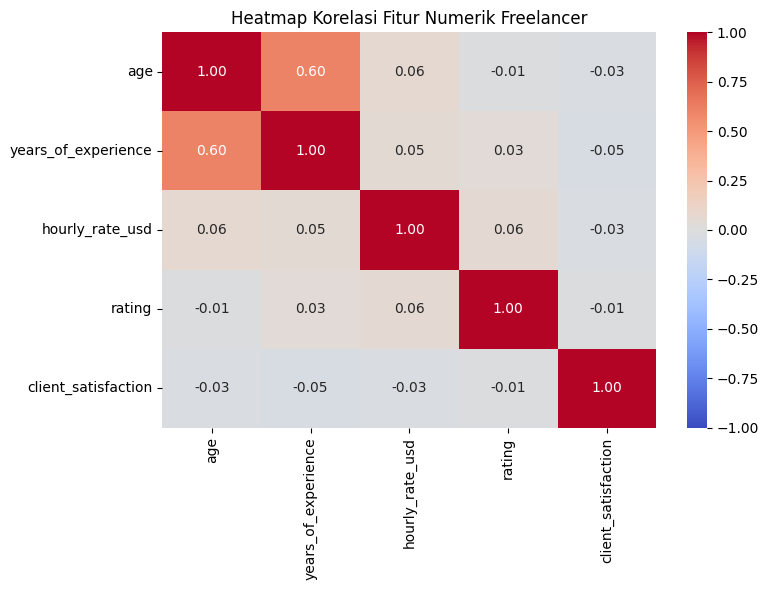

=== KORELASI TARIF PER SKILL ===


,primary_skill,n,"r(pengalaman, tarif)","r(usia, tarif)"
0,AI,88,-0.054,0.062
1,Blockchain Development,96,-0.149,-0.173
2,Cybersecurity,84,0.071,0.111
3,Data Analysis,89,0.038,0.137
4,DevOps,102,-0.083,-0.074
5,Graphic Design,85,0.162,0.048
6,Machine Learning,79,0.158,0.191
7,Mobile Apps,93,0.105,0.079
8,UI/UX Design,103,0.103,0.055
9,Web Development,92,0.186,0.228


In [108]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from IPython.display import display

# Korelasi Pearson antar fitur numerik
corr_matrix = df_pre[num_cols_uni].corr()
display(corr_matrix.round(2))

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Heatmap Korelasi Fitur Numerik Freelancer")
plt.tight_layout()
plt.show()

# Korelasi pengalaman dan usia terhadap tarif, per skill
rows = []
for skill, g in df_pre.groupby("primary_skill"):
    rows.append({
        "primary_skill": skill,
        "n": len(g),
        "r(pengalaman, tarif)": round(g["years_of_experience"].corr(g["hourly_rate_usd"]), 3),
        "r(usia, tarif)": round(g["age"].corr(g["hourly_rate_usd"]), 3),
    })
print("=== KORELASI TARIF PER SKILL ===")
display(pd.DataFrame(rows))

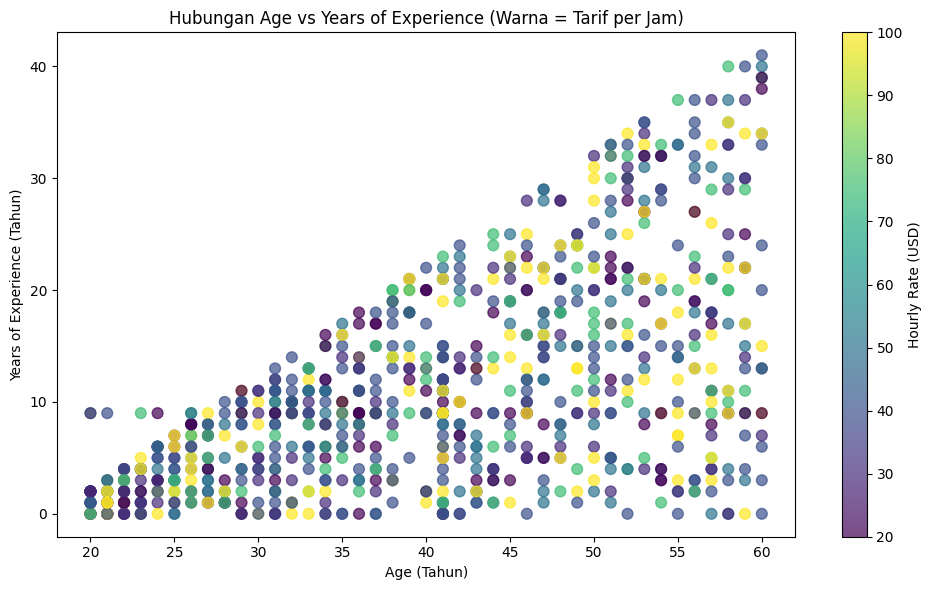

In [109]:
#Scatter plot ini memperlihatkan hubungan usia dan pengalaman, dengan warna sebagai tarif per jam.
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    df_pre["age"],
    df_pre["years_of_experience"],
    c=df_pre["hourly_rate_usd"],
    cmap="viridis",
    alpha=0.7,
    s=60,
)
plt.colorbar(scatter, label="Hourly Rate (USD)")
plt.title("Hubungan Age vs Years of Experience (Warna = Tarif per Jam)")
plt.xlabel("Age (Tahun)")
plt.ylabel("Years of Experience (Tahun)")
plt.tight_layout()
plt.show()


Visualisasi diatas menunjukkan bahwa fitur age naik beriringan dengan years of experince, jadi semakin besar umur seseorang semakin lama pula pengalamannya, namun gradasi warna untuk hourly ratenya cenderung agak menyebar, yang artinya tahun pengalaman dan umur seorang freelancer tidak selalu mempengaruhi tarif/hourly rate orang tersebut secara signifikan. Karenanya berikut analisis lanjutan terhadap hourly rate dan years experience setiap skill.

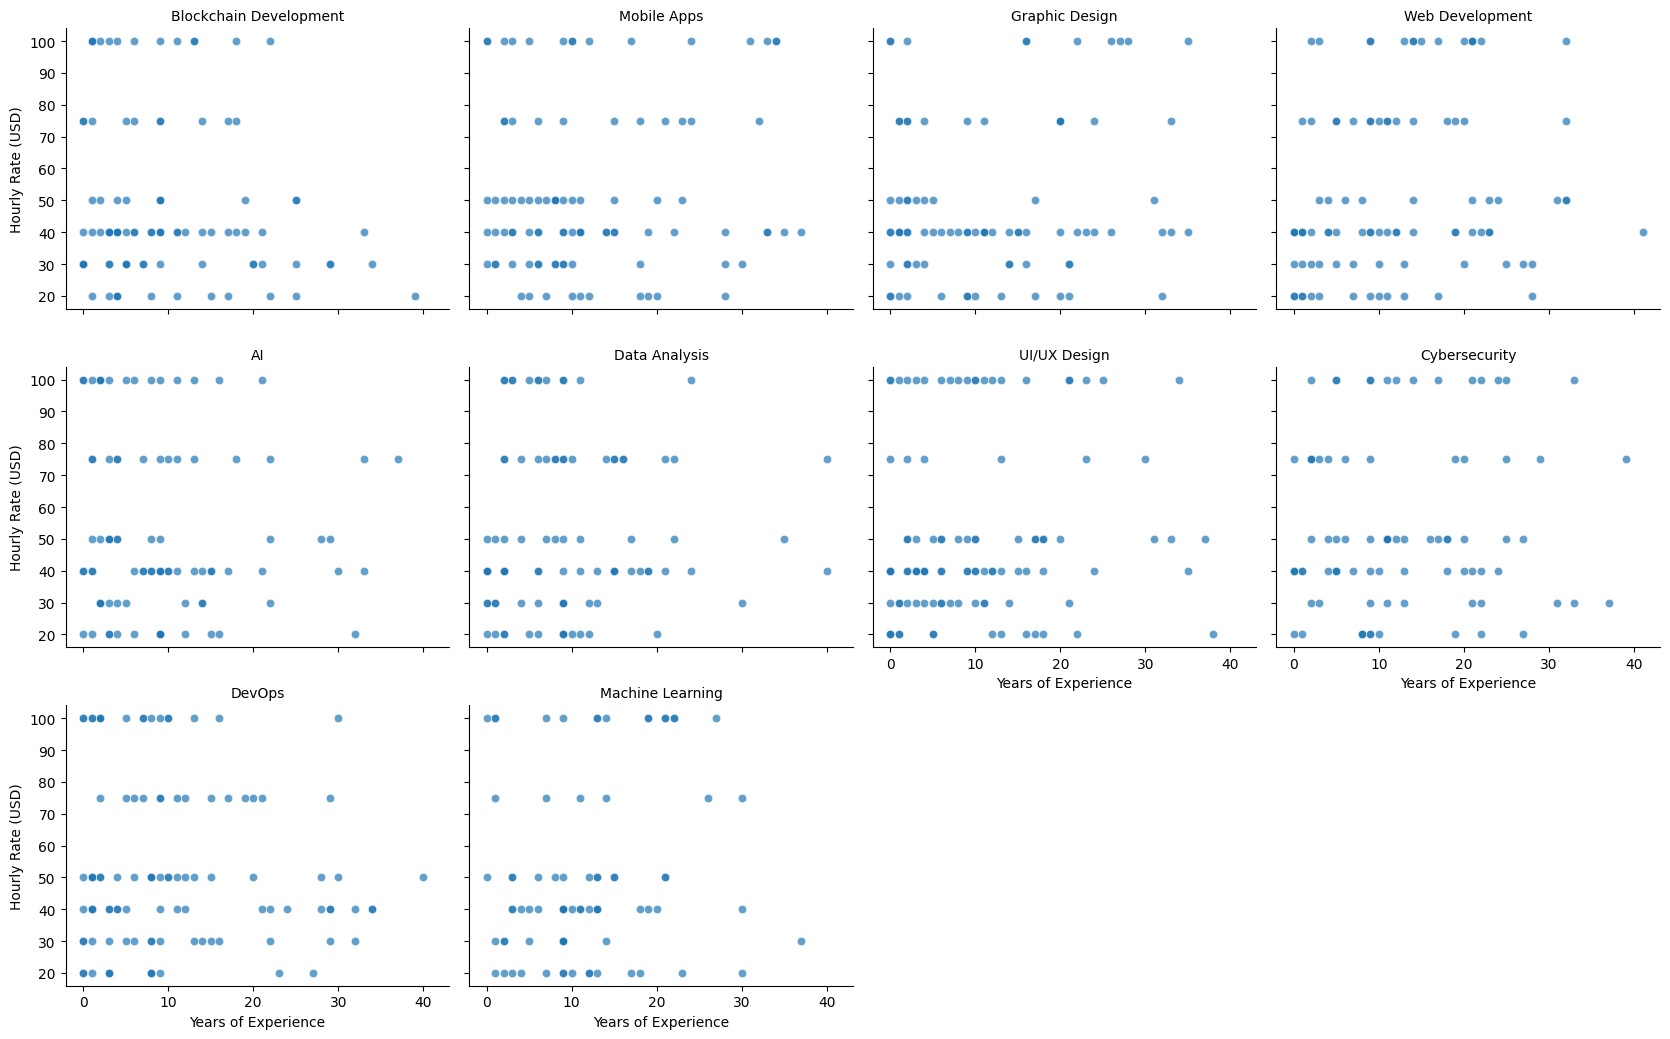

In [110]:
#Scatter plot per skill memeriksa apakah pola pengalaman dan tarif berbeda antar skill.
g = sns.FacetGrid(df_pre, col="primary_skill", col_wrap=4, height=3.5, aspect=1.2)
g.map_dataframe(
    sns.scatterplot,
    x="years_of_experience",
    y="hourly_rate_usd",
    alpha=0.7,
    color="tab:blue",
)
g.set_axis_labels("Years of Experience", "Hourly Rate (USD)")
g.set_titles(col_template="{col_name}")
plt.tight_layout()
plt.show()

Dari hasil analisis FacetGrid persebaran hourly rate dan years experience per skill dapat dilihat bahwa memang tidak ada korelasi spesifik antara kedua fitur ini, karena di tiap bidang keahlian sekalipun, years_of_experience tetap tidak menentukan besarnya hourly_rate_usd.


### 5.2 Tarif per Skill dan per Negara

Rata-rata dan simpangan baku tarif tiap skill ditampilkan bersama jumlah sampelnya. Pada heatmap negara × skill, sel dengan jumlah sampel kurang dari `MIN_N` tidak ditampilkan, karena rata-ratanya dihitung dari terlalu sedikit data.

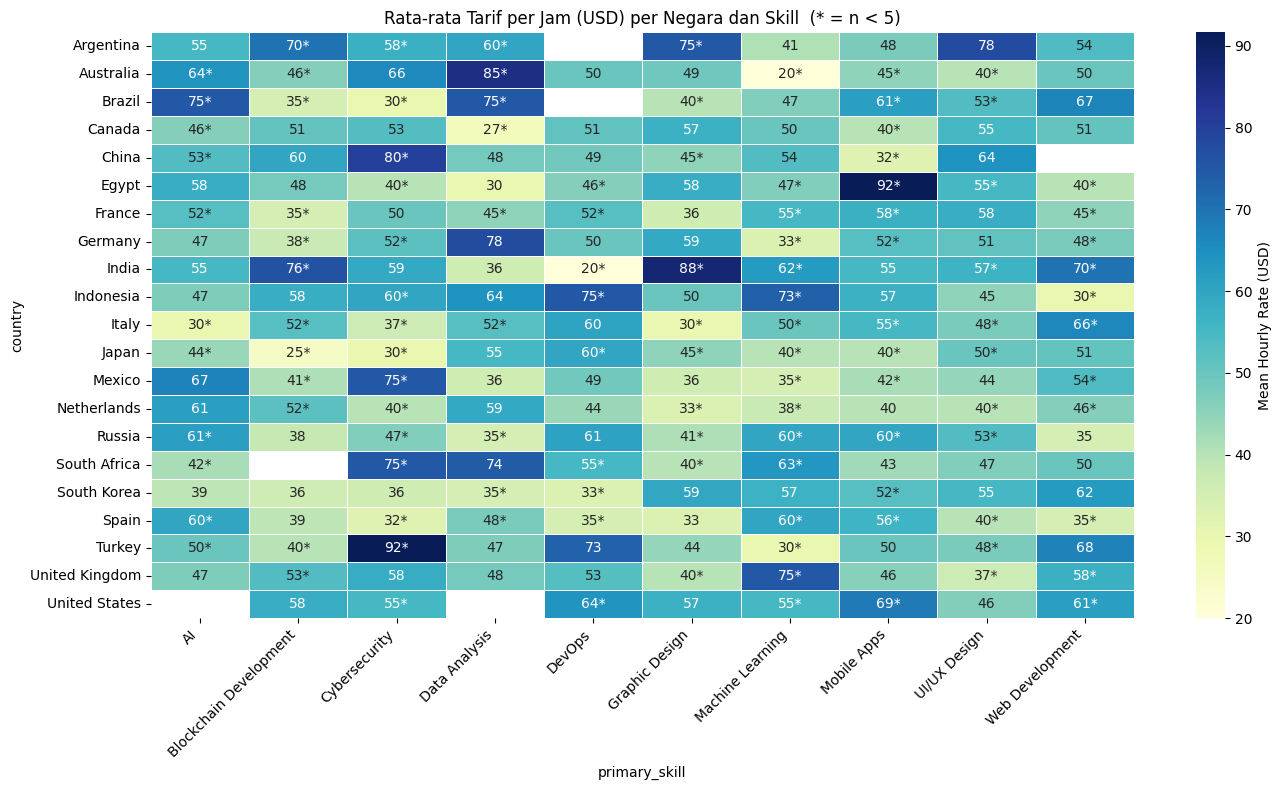

In [111]:
MIN_N = 5

pivot_mean = df_pre.pivot_table(
    index="country", columns="primary_skill",
    values="hourly_rate_usd", aggfunc="mean"
)
pivot_n = df_pre.pivot_table(
    index="country", columns="primary_skill",
    values="hourly_rate_usd", aggfunc="count"
).fillna(0)

# Buat label: angka + tanda * kalau n < MIN_N
annot_labels = pivot_mean.copy().astype(object)
for r in pivot_mean.index:
    for c in pivot_mean.columns:
        val = pivot_mean.loc[r, c]
        n   = pivot_n.loc[r, c] if r in pivot_n.index and c in pivot_n.columns else 0
        if pd.isna(val):
            annot_labels.loc[r, c] = ""
        elif n < MIN_N:
            annot_labels.loc[r, c] = f"{val:.0f}*"
        else:
            annot_labels.loc[r, c] = f"{val:.0f}"

plt.figure(figsize=(14, 8))
sns.heatmap(
    pivot_mean,
    annot=annot_labels,
    fmt="",                      # fmt="" karena annot sudah string
    cmap="YlGnBu",
    mask=pivot_mean.isna(),
    cbar_kws={"label": "Mean Hourly Rate (USD)"},
    linewidths=0.4,
)
plt.title("Rata-rata Tarif per Jam (USD) per Negara dan Skill  (* = n < 5)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### 5.3 Deteksi Outlier Multivariat (Isolation Forest & LOF)

Kedua algoritma dijalankan pada data yang sudah dinormalisasi. LOF berbasis jarak, sehingga tanpa normalisasi tarif (rentang 80) akan mendominasi rating (rentang 5). Isolation Forest tidak sensitif terhadap skala, tetapi tetap dijalankan pada data yang sama agar perbandingannya adil. Kedua metode memakai contamination 1% pada tahap ini sebagai tahap eksplorasi.

In [112]:
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from IPython.display import display

features_multi = ["age", "years_of_experience", "hourly_rate_usd", "rating", "client_satisfaction"]
X_scaled = df_normalized[features_multi]

# Isolation Forest
iso_eksplorasi = IsolationForest(contamination=0.01, random_state=42)
flag_iso_1 = iso_eksplorasi.fit_predict(X_scaled) == -1
score_iso_1 = iso_eksplorasi.decision_function(X_scaled)

# Local Outlier Factor
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.01)
flag_lof = lof.fit_predict(X_scaled) == -1
score_lof = lof.negative_outlier_factor_

overlap_1 = (flag_iso_1 & flag_lof).sum()
print(f"Outlier Isolation Forest (1%) : {flag_iso_1.sum()} baris")
print(f"Outlier LOF (1%)              : {flag_lof.sum()} baris")
print(f"Disepakati kedua algoritma    : {overlap_1} baris")

print("\n=== DATA OUTLIER ISOLATION FOREST (nilai asli) ===")
display(
    df_pre.loc[flag_iso_1, ["freelancer_id"] + features_multi]
    .assign(score_iforest=score_iso_1[flag_iso_1])
    .head(10)
)

print("\n=== DATA OUTLIER LOF (nilai asli) ===")
display(
    df_pre.loc[flag_lof, ["freelancer_id"] + features_multi]
    .assign(score_lof=score_lof[flag_lof])
    .head(10)
)

Outlier Isolation Forest (1%) : 10 baris
Outlier LOF (1%)              : 10 baris
Disepakati kedua algoritma    : 5 baris

=== DATA OUTLIER ISOLATION FOREST (nilai asli) ===


,freelancer_id,age,years_of_experience,hourly_rate_usd,rating,client_satisfaction,score_iforest
135,FL250136,60.0,39.0,75.0,1.4,70.0,-0.010031
325,FL250326,58.0,40.0,75.0,3.4,100.0,-0.054611
422,FL250423,60.0,34.0,100.0,0.0,74.0,-0.019319
455,FL250456,21.0,3.0,100.0,4.7,96.0,-0.005951
460,FL250461,53.0,35.0,40.0,5.0,62.0,-0.000078
545,FL250546,20.0,0.0,100.0,0.0,63.0,-0.017180
575,FL250576,60.0,9.0,100.0,0.0,96.0,-0.000727
629,FL250630,60.0,41.0,40.0,4.9,66.0,-0.015364
760,FL250761,60.0,40.0,50.0,4.6,100.0,-0.053218
985,FL250986,60.0,39.0,20.0,1.4,86.0,-0.023617



=== DATA OUTLIER LOF (nilai asli) ===


,freelancer_id,age,years_of_experience,hourly_rate_usd,rating,client_satisfaction,score_lof
128,FL250129,58.0,9.0,20.0,0.0,65.0,-1.298033
325,FL250326,58.0,40.0,75.0,3.4,100.0,-1.367803
337,FL250338,57.0,2.0,40.0,0.0,60.0,-1.304758
455,FL250456,21.0,3.0,100.0,4.7,96.0,-1.297346
545,FL250546,20.0,0.0,100.0,0.0,63.0,-1.343019
629,FL250630,60.0,41.0,40.0,4.9,66.0,-1.318750
701,FL250702,45.0,25.0,50.0,0.0,99.0,-1.268220
760,FL250761,60.0,40.0,50.0,4.6,100.0,-1.482622
959,FL250960,21.0,1.0,100.0,0.0,79.0,-1.264636
961,FL250962,21.0,1.0,100.0,0.0,95.0,-1.260056


### 5.4 Cleaning: Mahalanobis Distance dan Isolation Forest

Jarak Mahalanobis dibandingkan dengan threshold Chi-Square pada tingkat kepercayaan 99%. Threshold ini mengasumsikan data berdistribusi normal multivariat. Fitur pada dataset ini hampir uniform, sehingga asumsi tersebut tidak terpenuhi dan threshold hanya berfungsi sebagai acuan.

Estimator kovarians biasa sangat dipengaruhi oleh pencilan itu sendiri. Oleh karena itu, versi naif dan versi robust (Minimum Covariance Determinant, MCD) ditampilkan bersama.

Threshold Chi-Square 99%            : 15.086
Outlier Mahalanobis (naif)          : 4 baris
Outlier Mahalanobis (robust, MCD)   : 115 baris
Ekspektasi teoretis jika normal     : 9 baris
Outlier Isolation Forest (5%)        : 46 baris

=== SENSITIVITAS TERHADAP CONTAMINATION ===


,contamination,outlier IF,outlier IF atau MCD
0,0.01,10,117
1,0.02,19,122
2,0.05,46,136
3,0.10,91,160



Baris yang ditandai Mahalanobis (MCD) : 115
Baris yang ditandai Isolation Forest  : 46
Irisan keduanya                       : 25
Total baris dibuang (OR)              : 136
Dimensi data bersih                   : (775, 12)


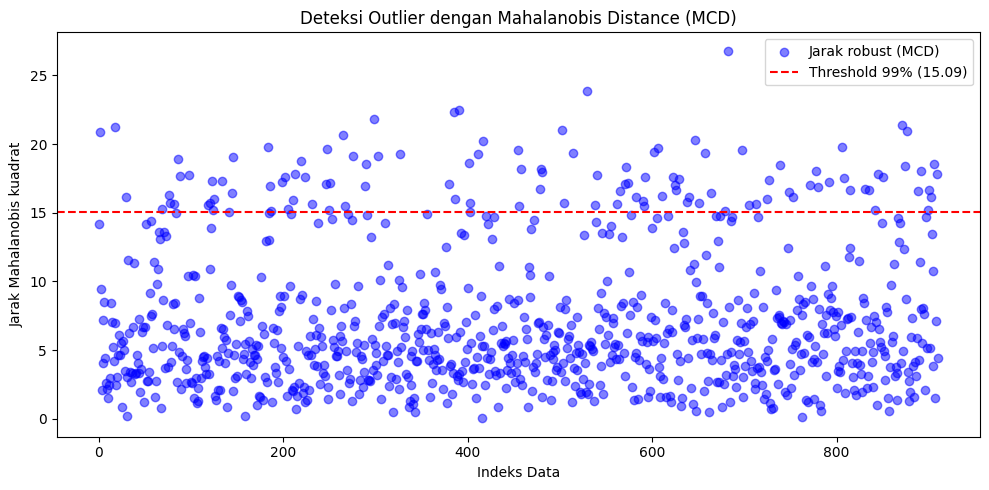

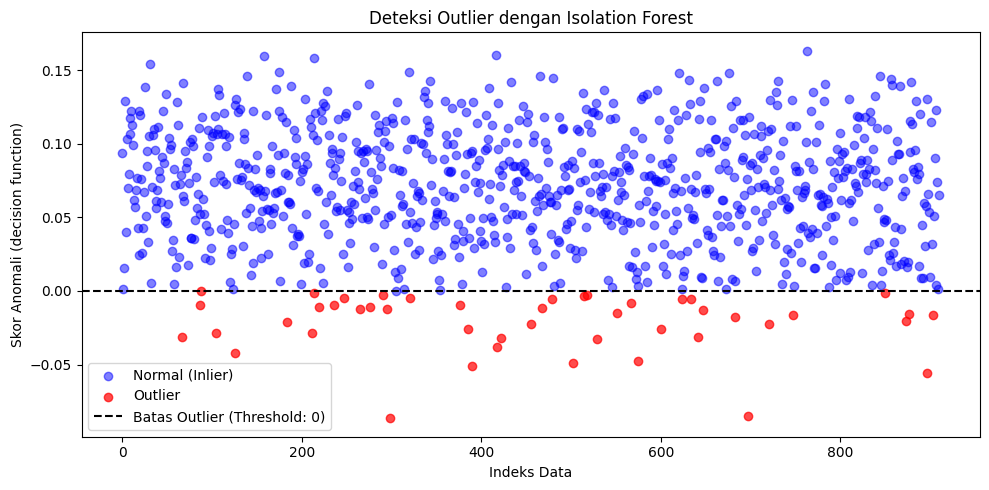

In [113]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from sklearn.covariance import EmpiricalCovariance, MinCovDet
from sklearn.ensemble import IsolationForest

# Jarak Mahalanobis kuadrat (d2)
emp_cov = EmpiricalCovariance().fit(X_scaled)
d2_naive = emp_cov.mahalanobis(X_scaled)

mcd = MinCovDet(random_state=42).fit(X_scaled)
d2_robust = mcd.mahalanobis(X_scaled)

# Threshold Chi-Square 99% dengan derajat bebas = jumlah fitur
threshold_mah = chi2.ppf(0.99, df=X_scaled.shape[1])
flag_mah_naive = d2_naive > threshold_mah
flag_mah = d2_robust > threshold_mah

print(f"Threshold Chi-Square 99%            : {threshold_mah:.3f}")
print(f"Outlier Mahalanobis (naif)          : {flag_mah_naive.sum()} baris")
print(f"Outlier Mahalanobis (robust, MCD)   : {flag_mah.sum()} baris")
print(f"Ekspektasi teoretis jika normal     : {0.01 * len(X_scaled):.0f} baris")

# Isolation Forest untuk cleaning
CONTAM_CLEAN = 0.05
iso_clean = IsolationForest(contamination=CONTAM_CLEAN, random_state=42)
flag_iso = iso_clean.fit_predict(X_scaled) == -1
print(f"Outlier Isolation Forest ({CONTAM_CLEAN:.0%})        : {flag_iso.sum()} baris")

# Sensitivitas: berapa baris dibuang pada beberapa nilai contamination
sens_rows = []
for c in [0.01, 0.02, 0.05, 0.10]:
    f_iso = IsolationForest(contamination=c, random_state=42).fit_predict(X_scaled) == -1
    sens_rows.append({
        "contamination": c,
        "outlier IF": int(f_iso.sum()),
        "outlier IF atau MCD": int((f_iso | flag_mah).sum()),
    })
print("\n=== SENSITIVITAS TERHADAP CONTAMINATION ===")
display(pd.DataFrame(sens_rows))

# Gabungan (OR) dan pembuatan data bersih
flag_out = flag_mah | flag_iso
print(f"\nBaris yang ditandai Mahalanobis (MCD) : {flag_mah.sum()}")
print(f"Baris yang ditandai Isolation Forest  : {flag_iso.sum()}")
print(f"Irisan keduanya                       : {(flag_mah & flag_iso).sum()}")
print(f"Total baris dibuang (OR)              : {flag_out.sum()}")

clean_mask = ~flag_out
df_clean = df_normalized[clean_mask].copy()
df_clean_raw = df_pre[clean_mask].copy()
df_clean.to_csv("global_freelancers_no_outliers.csv", index=False)
df_clean_raw.to_csv("global_freelancers_no_outliers_nilai_asli.csv", index=False)
print(f"Dimensi data bersih                   : {df_clean.shape}")

# Visualisasi jarak Mahalanobis
plt.figure(figsize=(10, 5))
plt.scatter(range(len(d2_robust)), d2_robust, color="blue", alpha=0.5, label="Jarak robust (MCD)")
plt.axhline(threshold_mah, color="red", linestyle="--", label=f"Threshold 99% ({threshold_mah:.2f})")
plt.title("Deteksi Outlier dengan Mahalanobis Distance (MCD)")
plt.xlabel("Indeks Data")
plt.ylabel("Jarak Mahalanobis kuadrat")
plt.legend()
plt.tight_layout()
plt.show()

# Visualisasi skor Isolation Forest
skor_iso = iso_clean.decision_function(X_scaled)
plt.figure(figsize=(10, 5))
plt.scatter(np.where(~flag_iso)[0], skor_iso[~flag_iso], color="blue", alpha=0.5, label="Normal (Inlier)")
plt.scatter(np.where(flag_iso)[0], skor_iso[flag_iso], color="red", alpha=0.7, label="Outlier")
plt.axhline(0, color="black", linestyle="--", label="Batas Outlier (Threshold: 0)")
plt.title("Deteksi Outlier dengan Isolation Forest")
plt.xlabel("Indeks Data")
plt.ylabel("Skor Anomali (decision function)")
plt.legend()
plt.tight_layout()
plt.show()

### 5.5 Silhouette Score Sesudah Cleaning

Perbandingan dilakukan dengan dua cara. Pertama, label K-Means dari data penuh dinilai ulang pada baris yang sama dengan data bersih, sehingga efek pembuangan baris terlihat tanpa pengaruh perubahan populasi. Kedua, K-Means dijalankan ulang pada data bersih.

In [114]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_full = df_normalized[features_multi]
X_clean = df_clean[features_multi]

# K-Means pada data penuh (sebelum cleaning)
kmeans_full = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_full)
labels_full = kmeans_full.labels_
sil_full = silhouette_score(X_full, labels_full)

# Baris yang sama, label yang sama
sil_full_same_rows = silhouette_score(X_full[np.asarray(clean_mask)], labels_full[np.asarray(clean_mask)])

# K-Means dijalankan ulang pada data bersih
kmeans_clean = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_clean)
sil_clean = silhouette_score(X_clean, kmeans_clean.labels_)

print("=== SILHOUETTE SCORE (k = 3) ===")
print(f"Sebelum cleaning, data penuh ({len(X_full)} baris)       : {sil_full:.4f}")
print(f"Baris yang sama, label sebelum cleaning ({len(X_clean)} baris): {sil_full_same_rows:.4f}")
print(f"Sesudah cleaning, K-Means dijalankan ulang ({len(X_clean)} baris): {sil_clean:.4f}")

print("\n=== SILHOUETTE PER k PADA DATA BERSIH ===")
for k in range(2, 9):
    labels_k = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_clean)
    print(f"k = {k}: {silhouette_score(X_clean, labels_k):.4f}")

=== SILHOUETTE SCORE (k = 3) ===
Sebelum cleaning, data penuh (911 baris)       : 0.2193
Baris yang sama, label sebelum cleaning (775 baris): 0.2132
Sesudah cleaning, K-Means dijalankan ulang (775 baris): 0.2110

=== SILHOUETTE PER k PADA DATA BERSIH ===
k = 2: 0.2026
k = 3: 0.2110
k = 4: 0.2069
k = 5: 0.1979
k = 6: 0.1928
k = 7: 0.1923
k = 8: 0.1953


### 6. Random Forest (Prediksi `is_active`)

Random Forest memprediksi status aktif dari lima fitur numerik. Beberapa langkah dilakukan agar hasilnya dapat dipercaya:
- **Stratified split** menjaga proporsi kelas tetap sama di data latih dan data uji.
- **Baseline** menebak kelas mayoritas, sebagai pembanding minimum.
- **Cross-validation 5-fold** memberi gambaran hasil yang tidak bergantung pada satu pembagian data.
- **Permutation importance** pada data uji menggantikan `feature_importances_` yang bias terhadap variabel kontinu.

=== PROPORSI KELAS is_active ===
is_active
0    0.525
1    0.475

Akurasi baseline (mayoritas) pada data uji : 0.523
Akurasi Random Forest pada data uji        : 0.516

CV 5-fold, Random Forest : 0.483 ± 0.021
CV 5-fold, baseline      : 0.525 ± 0.003

=== PERMUTATION IMPORTANCE (data uji) ===


,Fitur,Importance_mean,Importance_std
4,client_satisfaction,0.0471,0.0333
0,age,0.0368,0.0374
1,years_of_experience,0.0239,0.0269
3,rating,0.0135,0.0254
2,hourly_rate_usd,-0.0032,0.0166


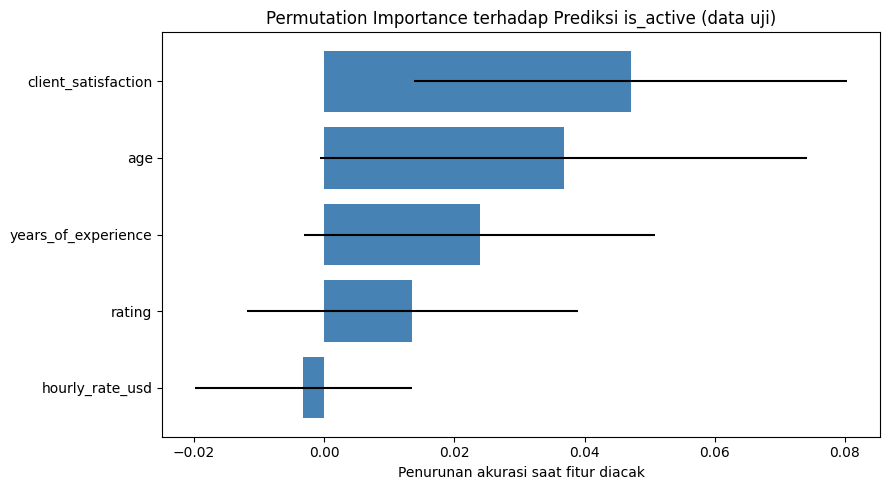

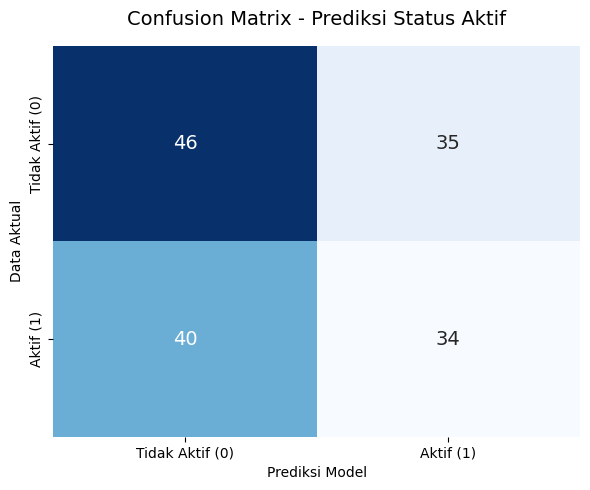


=== LAPORAN KLASIFIKASI (data uji) ===
              precision    recall  f1-score   support

           0      0.535     0.568     0.551        81
           1      0.493     0.459     0.476        74

    accuracy                          0.516       155
   macro avg      0.514     0.514     0.513       155
weighted avg      0.515     0.516     0.515       155



In [115]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.inspection import permutation_importance
from IPython.display import display

fitur = ["age", "years_of_experience", "hourly_rate_usd", "rating", "client_satisfaction"]
X_rf = df_clean[fitur]
y_rf = df_clean["is_active"]

print("=== PROPORSI KELAS is_active ===")
print(y_rf.value_counts(normalize=True).round(3).to_string())

X_train, X_test, y_train, y_test = train_test_split(
    X_rf, y_rf, test_size=0.2, stratify=y_rf, random_state=42
)

# Baseline: selalu menebak kelas mayoritas
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
acc_baseline = accuracy_score(y_test, baseline.predict(X_test))

# Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred)

print(f"\nAkurasi baseline (mayoritas) pada data uji : {acc_baseline:.3f}")
print(f"Akurasi Random Forest pada data uji        : {acc_rf:.3f}")

# Cross-validation 5-fold stratified
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rf = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42), X_rf, y_rf, cv=cv)
cv_base = cross_val_score(DummyClassifier(strategy="most_frequent"), X_rf, y_rf, cv=cv)
print(f"\nCV 5-fold, Random Forest : {cv_rf.mean():.3f} ± {cv_rf.std():.3f}")
print(f"CV 5-fold, baseline      : {cv_base.mean():.3f} ± {cv_base.std():.3f}")

# Permutation importance pada data uji
perm = permutation_importance(rf_model, X_test, y_test, n_repeats=10, random_state=42, scoring="accuracy")
perm_df = (
    pd.DataFrame({
        "Fitur": fitur,
        "Importance_mean": perm.importances_mean,
        "Importance_std": perm.importances_std,
    })
    .sort_values("Importance_mean", ascending=False)
)
print("\n=== PERMUTATION IMPORTANCE (data uji) ===")
display(perm_df.round(4))

plt.figure(figsize=(9, 5))
plt.barh(perm_df["Fitur"], perm_df["Importance_mean"], xerr=perm_df["Importance_std"], color="steelblue")
plt.gca().invert_yaxis()
plt.title("Permutation Importance terhadap Prediksi is_active (data uji)")
plt.xlabel("Penurunan akurasi saat fitur diacak")
plt.tight_layout()
plt.show()

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["Tidak Aktif (0)", "Aktif (1)"],
    yticklabels=["Tidak Aktif (0)", "Aktif (1)"],
    annot_kws={"size": 14},
)
plt.title("Confusion Matrix - Prediksi Status Aktif", fontsize=14, pad=15)
plt.xlabel("Prediksi Model")
plt.ylabel("Data Aktual")
plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI (data uji) ===")
print(classification_report(y_test, y_pred, digits=3))

# KESIMPULAN

## Kesimpulan Umum
Dataset freelancer ini relatif bersih dan seimbang, tetapi hubungan antarvariabelnya lemah. Satu-satunya pola yang jelas adalah usia yang berkaitan dengan pengalaman. Tarif per jam tidak dipengaruhi oleh pengalaman maupun skill, dan status aktif tidak dapat diprediksi dari fitur numerik yang tersedia. Outlier yang ditemukan sedikit dan lebih berupa kombinasi nilai yang janggal daripada kesalahan pencatatan. Struktur klaster yang terbentuk juga tergolong lemah.
## 1. Preprocessing & Normalisasi
Data mentah dibersihkan dengan menghapus simbol `USD`, `$`, dan `%`, serta menyeragamkan kategori `gender` dan `is_active`. Sebanyak **89 baris** dengan label `is_active` kosong dibuang karena label tidak boleh diisi dengan tebakan. Missing value pada kolom numerik diisi menggunakan **median**. Lima fitur numerik kontinu kemudian dinormalisasi dengan **Min-Max Scaler** ke rentang 0–1. Data setelah preprocessing berjumlah **911 baris dan 12 kolom**.

## 2. Silhouette Score Sebelum Cleaning
- K-Means dengan k = 3 pada 911 baris menghasilkan Silhouette Score **0,2193**.

Nilai tersebut menunjukkan struktur klaster yang relatif lemah. Nilai tertinggi dari k yang diuji sebelum cleaning adalah k = 2 dengan skor 0,2479.

## 3. Analisis Univariat
- **Numerik:** rata-rata usia 40,33 tahun, pengalaman 11,14 tahun, tarif $51,63/jam, rating 2,49, dan kepuasan klien 79,16. Freelancer aktif berjumlah **446 orang (48,96%)**, sedangkan tidak aktif 465 orang (51,04%).
- **Kategorikal:** gender relatif seimbang (Male 51,81%, Female 48,19%). Negara terbanyak adalah South Korea dan Canada (masing-masing 6,70%), bahasa terbanyak English (21,51%), dan skill terbanyak UI/UX Design (11,31%). Persebaran skill relatif merata, yaitu 8,67%–11,31%.
- **Redundansi:** setiap negara hanya memiliki satu bahasa pada dataset, sehingga `language` sepenuhnya ditentukan oleh `country`. Untuk pemodelan, keduanya tidak perlu digunakan bersamaan.
- **Outlier (IQR):** hanya `years_of_experience` yang memiliki outlier, sebanyak **6 data (0,66%)**.

## 4. Analisis Multivariat
- **Korelasi keseluruhan:** `age` dan `years_of_experience` berkorelasi positif sedang (r = **0,60**). Korelasi tarif dengan pengalaman sebesar **0,05** dan dengan usia sebesar **0,06**, sehingga hubungan keduanya dengan tarif sangat lemah.
- **Korelasi tarif per skill:** hubungan pengalaman dengan tarif berkisar **-0,149 hingga 0,186**, sedangkan hubungan usia dengan tarif berkisar **-0,173 hingga 0,228**. Nilai tersebut menunjukkan korelasi yang lemah pada seluruh skill.
- **Tarif per skill:** rata-rata tarif berkisar **$48,23–$53,75/jam**, dengan simpangan baku **$24,68–$27,90**. Perbedaan rata-rata tarif antar skill tidak besar.
- **Tarif per negara dan skill:** kombinasi dengan n < 5 disembunyikan. Sebanyak **124 dari 210 kombinasi** tidak ditampilkan karena jumlah datanya kurang dari 5.

## 5.3–5.4 Deteksi Outlier dan Cleaning
- **Isolation Forest** dan **LOF** (contamination 1%, data ternormalisasi) masing-masing menandai **10 baris**, dengan kesepakatan **5 baris**. Contoh kombinasi yang terdeteksi adalah freelancer berusia 20 tahun, pengalaman 0 tahun, dan tarif $100/jam.
- **Mahalanobis (MCD, Chi-Square 99%)** menandai **115 baris**, sedangkan Mahalanobis naif menandai 4 baris. Threshold Chi-Square adalah **15,086**. Jumlah outlier robust yang besar dibandingkan ekspektasi teoretis 9 baris menunjukkan bahwa asumsi distribusi normal mungkin tidak sesuai, sehingga hasilnya perlu dipandang sebagai acuan, bukan bukti kesalahan data.
- **Isolation Forest** (contamination 5%) menandai **46 baris**. Gabungan Mahalanobis MCD dan Isolation Forest (OR) menghasilkan **136 baris** yang dibuang, sehingga tersisa **775 baris dan 12 kolom**.
- **Sensitivitas contamination:** gabungan OR menandai 117 baris pada contamination 1%, 122 baris pada 2%, 136 baris pada 5%, dan 160 baris pada 10%. Jumlah data yang dibuang meningkat ketika contamination dinaikkan.

## 5.5 Silhouette Score Sesudah Cleaning
- Data penuh sebelum cleaning (911 baris): **0,2193**.
- Baris yang sama dengan label K-Means sebelum cleaning (775 baris): **0,2132**.
- Setelah cleaning dan K-Means dijalankan ulang (775 baris): **0,2110**.

Perubahan dari **0,2132 menjadi 0,2110** menunjukkan bahwa cleaning **tidak memperbaiki** pemisahan klaster; skor sedikit menurun. Pada data bersih, k = 3 menghasilkan skor tertinggi di antara k = 2–8 yang diuji, yaitu **0,2110**, tetapi struktur klaster tetap tergolong lemah.

## 6. Random Forest (Prediksi `is_active`)
Model memprediksi status aktif dari lima fitur numerik pada data bersih dengan stratified split 80:20. Akurasi Random Forest pada data uji adalah **0,516 (51,6%)**, sedikit lebih rendah daripada baseline mayoritas **0,523 (52,3%)**. Rata-rata cross-validation 5-fold Random Forest adalah **0,483 ± 0,021**, sedangkan baseline **0,525 ± 0,003**.

Permutation importance menunjukkan fitur paling berpengaruh adalah **client_satisfaction (0,0471)**, diikuti **age (0,0368)**, **years_of_experience (0,0239)**, dan **rating (0,0135)**. `hourly_rate_usd` memiliki importance **-0,0032**, sehingga pengacakan fitur tersebut tidak menurunkan akurasi pada evaluasi ini.

Secara keseluruhan, Random Forest belum melampaui baseline. Dengan demikian, lima fitur numerik yang digunakan belum cukup untuk memprediksi status aktif freelancer secara efektif. Diperlukan fitur tambahan yang relevan atau pendekatan pemodelan lain untuk meningkatkan prediksi.
